# Member 2 — Task 3: LightGBM Hyperparameter Optimization with Optuna

**Role:** Member 2 (LightGBM Lead)  
**Branch:** `feat/m2-task3-lgbm-optuna`  
**Primary Objective:** Maximize **Stratified 5-Fold CV AUPRC** (`nn_data_pipeline.evaluate_auprc`)  
**Dataset:** `processed_data/train_lgbm.parquet` (`699,960` rows, `35` engineered features).

### Two-Stage Leak-Free Tuning Strategy
1. **Stage 1 — Optuna Bayesian Search (`35 trials`, `TPESampler` + `MedianPruner`):**
   - Evaluates candidate hyperparameters across the first 3 stratified folds (`fold in {0, 1, 2}`, strictly from `train_folds.csv`) with `n_estimators=1500` and `stopping_rounds=50`, pruning weak trials immediately after Fold 0.
   - Tunes all required core parameters (`learning_rate`, `num_leaves`, `max_depth`, `colsample_bytree`, `subsample` with `subsample_freq=1`) plus regularization (`min_child_samples`, `reg_alpha`, `reg_lambda`) and soft class weight `scale_pos_weight` in `[1.0, 10.0]` guided by Task 2.
2. **Stage 2 — Full 5-Fold Confirmation & Low-LR Refinement:**
   - Re-evaluates the Top 3 distinct Optuna trials plus a lower learning-rate refinement (`learning_rate=0.02`, `n_estimators=4000`, `stopping_rounds=100`) on **all 5 folds (`699,960` rows)** to lock the true highest **OOF AUPRC** without single-fold or 3-fold selection bias.

## 1. Load Dataset, Task 2 Anchor & Configure Optuna Study

In [1]:
import os, sys
PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import json
import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns

from lgbm.lgbm_pipeline import (
    FOLD_COL,
    N_SPLITS,
    SEED,
    TARGET_COL,
    load_lgbm_datasets,
    run_lgbm_cv,
)
from data_pipeline.nn_data_pipeline import evaluate_auprc

warnings.filterwarnings("ignore", message=".*eval_set.*")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

train_df, test_df, feature_cols, cat_cols = load_lgbm_datasets()
X_all = train_df[feature_cols]
y_all = train_df[TARGET_COL].astype(np.int64).to_numpy()
folds = train_df[FOLD_COL].to_numpy()

with open("lgbm_imbalance_config.json", "r", encoding="utf-8") as f:
    imb_cfg = json.load(f)

print(f"Train shape   : {train_df.shape} | Features: {len(feature_cols)}")
print(
    f"Task 2 Anchor : {imb_cfg['strategy']} | "
    f"OOF AUPRC={imb_cfg['oof_auprc']:.6f} | Mean 5F={imb_cfg['mean_fold_auprc']:.6f}"
)

N_TRIALS = 35
SEARCH_FOLDS = [0, 1, 2]
TUNE_STOPPING_ROUNDS = 50
TUNE_MAX_ESTIMATORS = 1500

Train shape   : (699960, 38) | Features: 35
Task 2 Anchor : Moderate Weight (spw=5.0) | OOF AUPRC=0.499789 | Mean 5F=0.500230


## 2. Stage 1 — Run 35-Trial Optuna Search with TPE & Median Pruning

In [2]:
search_splits = [
    (k, np.flatnonzero(folds != k), np.flatnonzero(folds == k))
    for k in SEARCH_FOLDS
]


def objective(trial: optuna.Trial) -> float:
    learning_rate = trial.suggest_float("learning_rate", 0.025, 0.12, log=True)
    max_depth = trial.suggest_int("max_depth", 3, 10)
    max_possible_leaves = min(127, (2 ** max_depth) - 1)
    num_leaves = trial.suggest_int("num_leaves", 7, max(8, max_possible_leaves))
    colsample_bytree = trial.suggest_float("colsample_bytree", 0.40, 1.00)
    subsample = trial.suggest_float("subsample", 0.55, 1.00)
    min_child_samples = trial.suggest_int("min_child_samples", 20, 300)
    reg_alpha = trial.suggest_float("reg_alpha", 1e-3, 25.0, log=True)
    reg_lambda = trial.suggest_float("reg_lambda", 1e-3, 35.0, log=True)
    scale_pos_weight = trial.suggest_float("scale_pos_weight", 1.0, 10.0)

    params = {
        "objective": "binary",
        "metric": "average_precision",
        "boosting_type": "gbdt",
        "learning_rate": learning_rate,
        "n_estimators": TUNE_MAX_ESTIMATORS,
        "num_leaves": num_leaves,
        "max_depth": max_depth,
        "colsample_bytree": colsample_bytree,
        "subsample": subsample,
        "subsample_freq": 1 if subsample < 0.999 else 0,
        "min_child_samples": min_child_samples,
        "reg_alpha": reg_alpha,
        "reg_lambda": reg_lambda,
        "scale_pos_weight": scale_pos_weight,
        "random_state": SEED,
        "bagging_seed": SEED,
        "feature_fraction_seed": SEED,
        "n_jobs": -1,
        "verbose": -1,
    }

    fold_scores = []
    best_iters = []

    for step_idx, (fold_id, tr_idx, va_idx) in enumerate(search_splits):
        X_tr, y_tr = X_all.iloc[tr_idx], y_all[tr_idx]
        X_va, y_va = X_all.iloc[va_idx], y_all[va_idx]

        model = lgb.LGBMClassifier(**params)
        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_va, y_va)],
            eval_metric="average_precision",
            categorical_feature=cat_cols,
            callbacks=[lgb.early_stopping(stopping_rounds=TUNE_STOPPING_ROUNDS, verbose=False)],
        )
        best_iter = int(model.best_iteration_ or TUNE_MAX_ESTIMATORS)
        best_iters.append(best_iter)

        val_preds = model.predict_proba(X_va, num_iteration=best_iter)[:, 1]
        fold_auprc = evaluate_auprc(y_va, val_preds)
        fold_scores.append(fold_auprc)

        running_mean = float(np.mean(fold_scores))
        trial.report(running_mean, step=step_idx)
        if trial.should_prune():
            print(f"[Trial {trial.number:02d}] PRUNED at step {step_idx} (running={running_mean:.5f})", flush=True)
            raise optuna.TrialPruned()

    mean_score = float(np.mean(fold_scores))
    trial.set_user_attr("avg_best_iter", float(np.mean(best_iters)))
    print(
        f"[Trial {trial.number:02d}] COMPLETE | 3F AUPRC={mean_score:.6f} "
        f"| lr={learning_rate:.4f} leaves={num_leaves} depth={max_depth} "
        f"col={colsample_bytree:.2f} sub={subsample:.2f} min_ch={min_child_samples} "
        f"a={reg_alpha:.2f} l={reg_lambda:.2f} spw={scale_pos_weight:.2f} iter={np.mean(best_iters):.0f}",
        flush=True,
    )
    return mean_score


sampler = optuna.samplers.TPESampler(seed=SEED, multivariate=True)
pruner = optuna.pruners.MedianPruner(n_startup_trials=6, n_warmup_steps=0, interval_steps=1)

study = optuna.create_study(
    study_name="lgbm_fraud_auprc_optuna",
    direction="maximize",
    sampler=sampler,
    pruner=pruner,
)

# Warm-start with Task 2 anchor and regularized shallow-tree priors
study.enqueue_trial(
    {
        "learning_rate": 0.05,
        "max_depth": 10,
        "num_leaves": 31,
        "colsample_bytree": 1.0,
        "subsample": 1.0,
        "min_child_samples": 20,
        "reg_alpha": 1e-3,
        "reg_lambda": 1e-3,
        "scale_pos_weight": float(imb_cfg["effective_spw"]),
    }
)
study.enqueue_trial(
    {
        "learning_rate": 0.04,
        "max_depth": 5,
        "num_leaves": 23,
        "colsample_bytree": 0.65,
        "subsample": 0.80,
        "min_child_samples": 120,
        "reg_alpha": 2.0,
        "reg_lambda": 10.0,
        "scale_pos_weight": 5.0,
    }
)
study.enqueue_trial(
    {
        "learning_rate": 0.035,
        "max_depth": 4,
        "num_leaves": 15,
        "colsample_bytree": 0.55,
        "subsample": 0.78,
        "min_child_samples": 150,
        "reg_alpha": 1.5,
        "reg_lambda": 10.0,
        "scale_pos_weight": 7.5,
    }
)

t0 = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
opt_elapsed = time.perf_counter() - t0

completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
pruned = [t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED]

print(f"\nStage 1 Optuna finished in {opt_elapsed:.1f}s | Complete: {len(completed)} | Pruned: {len(pruned)}")
print(f"Best 3-Fold Trial #{study.best_trial.number} | 3F Mean AUPRC: {study.best_value:.6f}")
print("Best Stage-1 Params:")
print(json.dumps(study.best_params, indent=2))

[Trial 00] COMPLETE | 3F AUPRC=0.502408 | lr=0.0500 leaves=31 depth=10 col=1.00 sub=1.00 min_ch=20 a=0.00 l=0.00 spw=5.00 iter=232
[Trial 01] COMPLETE | 3F AUPRC=0.511443 | lr=0.0400 leaves=23 depth=5 col=0.65 sub=0.80 min_ch=120 a=2.00 l=10.00 spw=5.00 iter=522
[Trial 02] COMPLETE | 3F AUPRC=0.513756 | lr=0.0350 leaves=15 depth=4 col=0.55 sub=0.78 min_ch=150 a=1.50 l=10.00 spw=7.50 iter=780
[Trial 03] COMPLETE | 3F AUPRC=0.500342 | lr=0.0450 leaves=95 depth=10 col=0.76 sub=0.62 min_ch=63 a=0.00 l=8.63 spw=6.41 iter=184
[Trial 04] COMPLETE | 3F AUPRC=0.503391 | lr=0.0759 leaves=8 depth=3 col=0.90 sub=0.65 min_ch=71 a=0.01 l=0.02 spw=5.72 iter=532
[Trial 05] COMPLETE | 3F AUPRC=0.511794 | lr=0.0492 leaves=22 depth=5 col=0.48 sub=0.68 min_ch=122 a=0.10 l=3.70 spw=2.80 iter=490
[Trial 06] PRUNED at step 0 (running=0.48931)
[Trial 07] COMPLETE | 3F AUPRC=0.514397 | lr=0.0403 leaves=8 depth=3 col=0.66 sub=0.60 min_ch=159 a=0.00 l=13.55 spw=3.33 iter=993
[Trial 08] PRUNED at step 0 (running=

## 3. Stage 2 — Full 5-Fold Confirmation (Top 3 Trials + Low-LR Refinement)

In [3]:
def build_lgbm_params(raw_p: dict, n_estimators: int = 4000, lr_override: float | None = None) -> dict:
    sub = float(raw_p["subsample"])
    return {
        "objective": "binary",
        "metric": "average_precision",
        "boosting_type": "gbdt",
        "learning_rate": float(lr_override if lr_override is not None else raw_p["learning_rate"]),
        "n_estimators": int(n_estimators),
        "num_leaves": int(raw_p["num_leaves"]),
        "max_depth": int(raw_p["max_depth"]),
        "colsample_bytree": float(raw_p["colsample_bytree"]),
        "subsample": sub,
        "subsample_freq": 1 if sub < 0.999 else 0,
        "min_child_samples": int(raw_p["min_child_samples"]),
        "reg_alpha": float(raw_p["reg_alpha"]),
        "reg_lambda": float(raw_p["reg_lambda"]),
        "scale_pos_weight": float(raw_p["scale_pos_weight"]),
        "random_state": SEED,
        "n_jobs": -1,
        "verbose": -1,
    }


top_trials = sorted(completed, key=lambda t: t.value, reverse=True)[:3]
candidates = []
for rank, tr in enumerate(top_trials, start=1):
    candidates.append((f"Top-{rank} (Trial #{tr.number})", tr.number, build_lgbm_params(tr.params, n_estimators=4000)))

# Also evaluate a low-LR refinement on the #1 Optuna architecture
best_t = top_trials[0]
candidates.append(
    (
        f"Top-1 Low-LR Refined (Trial #{best_t.number}, lr=0.02)",
        best_t.number,
        build_lgbm_params(best_t.params, n_estimators=5000, lr_override=0.02),
    )
)

confirm_rows = []
confirm_results = {}
for label, trial_num, cand_params in candidates:
    print(f"\n>>> Full 5-Fold Verification: {label}")
    res = run_lgbm_cv(
        train_df=train_df,
        feature_cols=feature_cols,
        params=cand_params,
        cat_cols=cat_cols,
        spw_mode=None,
        stopping_rounds=100,
        verbose=True,
    )
    confirm_results[label] = (trial_num, cand_params, res)
    confirm_rows.append(
        {
            "Candidate": label,
            "Trial_Num": trial_num,
            "LR": cand_params["learning_rate"],
            "Depth": cand_params["max_depth"],
            "Leaves": cand_params["num_leaves"],
            "ColSample": round(cand_params["colsample_bytree"], 3),
            "SubSample": round(cand_params["subsample"], 3),
            "SPW": round(cand_params["scale_pos_weight"], 3),
            "Mean_5F_AUPRC": res["mean_auprc"],
            "Std_5F_AUPRC": res["std_auprc"],
            "OOF_AUPRC": res["metrics"]["auprc"],
            "OOF_ROC_AUC": res["metrics"]["roc_auc"],
            "Best_F1": res["metrics"]["best_f1"],
            "Avg_Best_Iter": float(np.mean(res["best_iterations"])),
        }
    )

confirm_df = pd.DataFrame(confirm_rows).sort_values("OOF_AUPRC", ascending=False).reset_index(drop=True)
print("\n=== Stage 2 Full 5-Fold Confirmation Leaderboard ===")
display(confirm_df)

winner_label = str(confirm_df.iloc[0]["Candidate"])
winner_trial_num, best_lgbm_params, res_tuned = confirm_results[winner_label]
print(f"\nSelected Final Tuned Winner: {winner_label} | OOF AUPRC={res_tuned['metrics']['auprc']:.6f}")

# Export study history and best hyperparameters JSON
trials_df = study.trials_dataframe()
trials_df.to_csv("optuna_lgbm_trials.csv", index=False)

artifact = {
    "winner_label": winner_label,
    "best_trial_number": int(winner_trial_num),
    "n_trials": N_TRIALS,
    "n_complete": len(completed),
    "n_pruned": len(pruned),
    "oof_auprc": float(res_tuned["metrics"]["auprc"]),
    "mean_fold_auprc": float(res_tuned["mean_auprc"]),
    "std_fold_auprc": float(res_tuned["std_auprc"]),
    "oof_roc_auc": float(res_tuned["metrics"]["roc_auc"]),
    "best_f1": float(res_tuned["metrics"]["best_f1"]),
    "best_threshold": float(res_tuned["metrics"]["best_threshold"]),
    "fold_auprcs": [float(x) for x in res_tuned["fold_auprcs"]],
    "best_iterations": [int(x) for x in res_tuned["best_iterations"]],
    "params": best_lgbm_params,
}
with open("best_lgbm_params.json", "w", encoding="utf-8") as f:
    json.dump(artifact, f, indent=2)

print("Saved best_lgbm_params.json and optuna_lgbm_trials.csv")


>>> Full 5-Fold Verification: Top-1 (Trial #29)
Fold 0 | AUPRC: 0.497926 | Best Iter: 1249
Fold 1 | AUPRC: 0.520518 | Best Iter: 1924
Fold 2 | AUPRC: 0.532373 | Best Iter: 1856
Fold 3 | AUPRC: 0.517486 | Best Iter: 1527
Fold 4 | AUPRC: 0.501339 | Best Iter: 2098
OOF AUPRC (Primary) : 0.513629
OOF ROC-AUC         : 0.947215
F1 @ 0.50           : 0.501455
Best F1             : 0.502849 @ threshold=0.4855 (P=0.5156, R=0.4907)
Confusion Matrix (Best Thresh):
[[682882   5389]
 [  5953   5736]]
Mean 5-Fold AUPRC: 0.513929 +/- 0.012735 | Avg Best Iter: 1730.8 | Time: 345.1s

>>> Full 5-Fold Verification: Top-2 (Trial #25)
Fold 0 | AUPRC: 0.497449 | Best Iter: 982
Fold 1 | AUPRC: 0.519658 | Best Iter: 1095
Fold 2 | AUPRC: 0.530750 | Best Iter: 1000
Fold 3 | AUPRC: 0.517023 | Best Iter: 1256
Fold 4 | AUPRC: 0.500199 | Best Iter: 1290
OOF AUPRC (Primary) : 0.512823
OOF ROC-AUC         : 0.947146
F1 @ 0.50           : 0.498546
Best F1             : 0.503406 @ threshold=0.5560 (P=0.5364, R=0.4742

,Candidate,Trial_Num,LR,Depth,Leaves,ColSample,SubSample,SPW,Mean_5F_AUPRC,Std_5F_AUPRC,OOF_AUPRC,OOF_ROC_AUC,Best_F1,Avg_Best_Iter
0,Top-1 (Trial #29),29,0.028805,4,11,0.462,0.958,3.359,0.513929,0.012735,0.513629,0.947215,0.502849,1730.8
1,"Top-1 Low-LR Refined (Trial #29, lr=0.02)",29,0.020000,4,11,0.462,0.958,3.359,0.513741,0.012761,0.513460,0.947209,0.502657,2029.0
2,Top-2 (Trial #25),25,0.032210,5,13,0.455,0.892,4.087,0.513016,0.012500,0.512823,0.947146,0.503406,1124.6
3,Top-3 (Trial #34),34,0.031668,6,18,0.410,0.848,1.244,0.512139,0.012653,0.511758,0.947023,0.503184,1096.2


## 4. Optuna Diagnostics: Optimization History & Hyperparameter Importance

Coreach.ai Comment -> LGBM Optuna Tuned (35 trials, Top-1 (Trial #29)) | CV OOF AUPRC: 0.5136 (Mean 5F: 0.5139 +/- 0.0127, Delta vs Task 2: +0.0138)


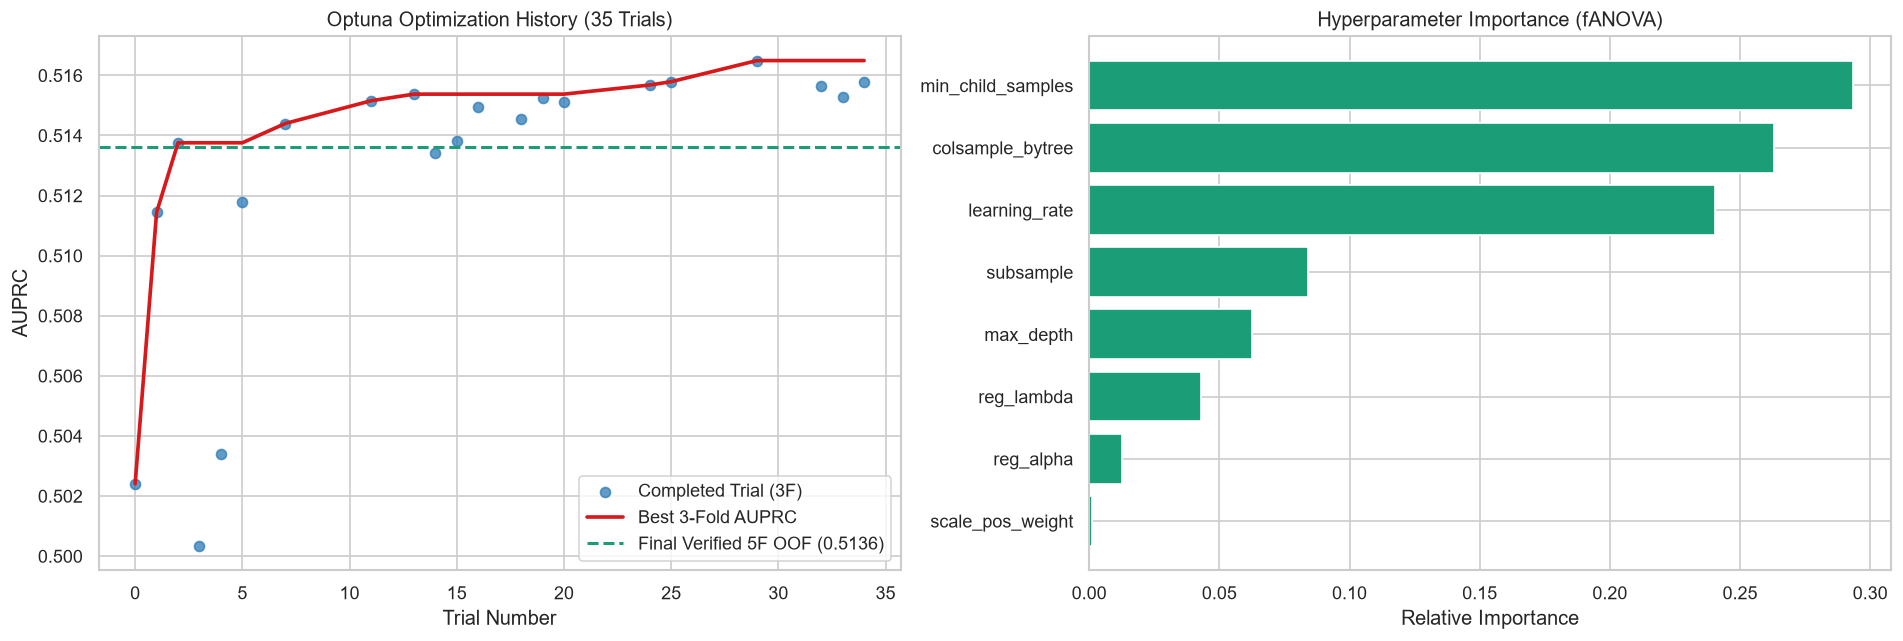

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Plot 1: Optimization History (Completed trials + Best-so-far line)
comp_df = trials_df[trials_df["state"] == "COMPLETE"].sort_values("number")
axes[0].scatter(comp_df["number"], comp_df["value"], alpha=0.75, label="Completed Trial (3F)", color="#2c7bb6")
axes[0].plot(
    comp_df["number"],
    comp_df["value"].cummax(),
    color="#d7191c",
    linewidth=2.2,
    label="Best 3-Fold AUPRC",
)
axes[0].axhline(
    res_tuned["metrics"]["auprc"],
    linestyle="--",
    color="#1b9e77",
    linewidth=1.8,
    label=f"Final Verified 5F OOF ({res_tuned['metrics']['auprc']:.4f})",
)
axes[0].set_xlabel("Trial Number")
axes[0].set_ylabel("AUPRC")
axes[0].set_title("Optuna Optimization History (35 Trials)")
axes[0].legend(loc="lower right")

# Plot 2: Hyperparameter Importance (fANOVA)
importances = optuna.importance.get_param_importances(
    study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED)
)
imp_df = pd.DataFrame(
    {"param": list(importances.keys()), "importance": list(importances.values())}
).iloc[::-1]
axes[1].barh(imp_df["param"], imp_df["importance"], color="#1b9e77")
axes[1].set_xlabel("Relative Importance")
axes[1].set_title("Hyperparameter Importance (fANOVA)")

plt.tight_layout()
plt.show()

delta_vs_t2 = res_tuned["metrics"]["auprc"] - imb_cfg["oof_auprc"]
print(
    f"Coreach.ai Comment -> LGBM Optuna Tuned ({N_TRIALS} trials, {winner_label}) "
    f"| CV OOF AUPRC: {res_tuned['metrics']['auprc']:.4f} "
    f"(Mean 5F: {res_tuned['mean_auprc']:.4f} +/- {res_tuned['std_auprc']:.4f}, "
    f"Delta vs Task 2: {delta_vs_t2:+.4f})"
)